B1 (field sweep, R=10): 8 pts
B2 (flow sweep,  R=10): 8 pts
B3 (field sweep, R=7 ): 5 pts
saved B_morphology.png


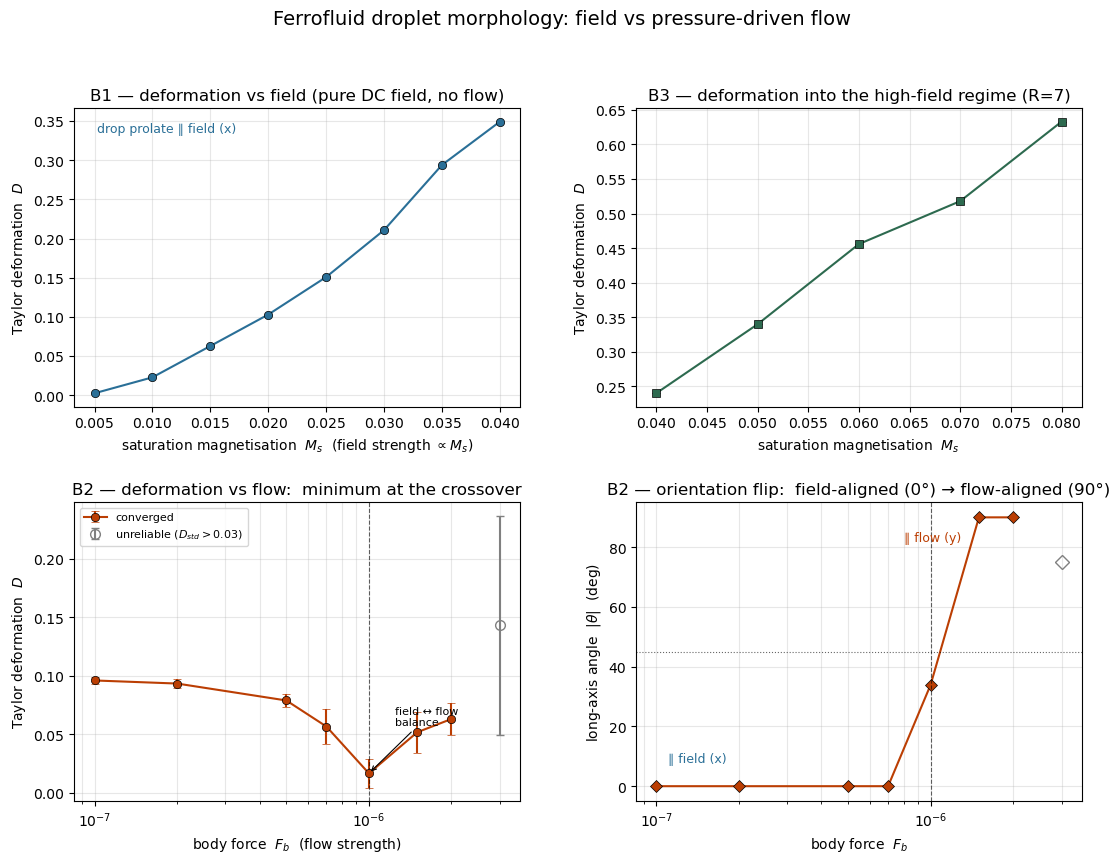

In [1]:
#!/usr/bin/env python3
"""
Visualise the B-test morphology results from the per-run summary.csv files.

  B1  deformation D vs field strength Ms      (FB=0, R=10)
  B2  field-vs-flow crossover: D and |angle| vs body force Fb   (FB>0, R=10)
  B3  deformation D vs field strength Ms, high range  (FB=0, R=7)

Each point is the tail-average (last 50% of iterations) of the limit cycle,
with the oscillation amplitude as an error bar.  Nothing is hardcoded --
everything is read from output_morphology/run_*/summary.csv, so re-running
after adding cases just works.  Points whose tail D_std is large (unconverged
/ chaotic, e.g. the strong-shear case) are drawn hollow and flagged.
"""
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE   = "output_morphology"
TAIL   = 0.5           # fraction of the run treated as converged tail
CHAOS  = 0.03          # D_std above this -> mark the point unreliable

# ---- parse every run folder --------------------------------------------
pat = re.compile(r"run_MS([0-9.eE+-]+)_FB([0-9.eE+-]+)_R([0-9.]+)_")
rows = []
for f in glob.glob(os.path.join(BASE, "run_*", "summary.csv")):
    m = pat.search(f)
    if not m:
        continue
    ms, fb, R = float(m.group(1)), float(m.group(2)), float(m.group(3))
    d = pd.read_csv(f)
    if d.empty:
        continue
    n = d.iter.max()
    t = d[d.iter >= TAIL * n]
    rows.append(dict(Ms=ms, Fb=fb, R=R, nsteps=int(n),
                     D=t.D.mean(), Dstd=t.D.std(),
                     absang=np.abs(t.ang).mean()))
df = pd.DataFrame(rows)
if df.empty:
    raise SystemExit(f"No summary.csv found under {BASE}/ -- run the sims first.")

# keep only the longest run for any duplicate (Ms,Fb,R)
df = (df.sort_values("nsteps")
        .drop_duplicates(subset=["Ms", "Fb", "R"], keep="last")
        .reset_index(drop=True))
df["bad"] = df.Dstd > CHAOS

# ---- split into the three experiments ----------------------------------
b1 = df[(df.Fb == 0) & (np.isclose(df.R, 10))].sort_values("Ms")
b3 = df[(df.Fb == 0) & (np.isclose(df.R, 7))].sort_values("Ms")
b2 = df[df.Fb > 0].sort_values("Fb")

print("B1 (field sweep, R=10):", len(b1), "pts")
print("B2 (flow sweep,  R=10):", len(b2), "pts")
print("B3 (field sweep, R=7 ):", len(b3), "pts")

# ---- plot ---------------------------------------------------------------
fig = plt.figure(figsize=(13, 9))
gs = fig.add_gridspec(2, 2, hspace=0.32, wspace=0.26)
C_FIELD, C_FLOW, C_B3 = "#2a6f97", "#bb3e03", "#2d6a4f"

# -- B1: D vs Ms --------------------------------------------------------
ax = fig.add_subplot(gs[0, 0])
ax.errorbar(b1.Ms, b1.D, yerr=b1.Dstd, fmt="o-", color=C_FIELD,
            ms=6, capsize=3, mec="k", mew=.5)
ax.set(xlabel=r"saturation magnetisation  $M_s$  (field strength $\propto M_s$)",
       ylabel=r"Taylor deformation  $D$",
       title="B1 — deformation vs field (pure DC field, no flow)")
ax.grid(alpha=.3)
ax.text(.05, .92, "drop prolate ∥ field (x)", transform=ax.transAxes,
        fontsize=9, color=C_FIELD)

# -- B3: D vs Ms, high range -------------------------------------------
ax = fig.add_subplot(gs[0, 1])
ax.errorbar(b3.Ms, b3.D, yerr=b3.Dstd, fmt="s-", color=C_B3,
            ms=6, capsize=3, mec="k", mew=.5)
ax.set(xlabel=r"saturation magnetisation  $M_s$",
       ylabel=r"Taylor deformation  $D$",
       title="B3 — deformation into the high-field regime (R=7)")
ax.grid(alpha=.3)

# -- B2 top: D vs Fb (the crossover) -----------------------------------
ax = fig.add_subplot(gs[1, 0])
good, bad = b2[~b2.bad], b2[b2.bad]
ax.errorbar(good.Fb, good.D, yerr=good.Dstd, fmt="o-", color=C_FLOW,
            ms=6, capsize=3, mec="k", mew=.5, label="converged")
if len(bad):
    ax.errorbar(bad.Fb, bad.D, yerr=bad.Dstd, fmt="o", mfc="none",
                color="0.5", ms=7, capsize=3,
                label=f"unreliable ($D_{{std}}>{CHAOS}$)")
# mark the deformation minimum (the balance point)
imin = good.D.idxmin()
fbmin = good.loc[imin, "Fb"]
ax.axvline(fbmin, color="k", ls="--", lw=.8, alpha=.6)
ax.annotate("field ↔ flow\nbalance", xy=(fbmin, good.D.min()),
            xytext=(fbmin*1.25, good.D.max()*.6), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=.8))
ax.set_xscale("log")
ax.set(xlabel=r"body force  $F_b$  (flow strength)",
       ylabel=r"Taylor deformation  $D$",
       title="B2 — deformation vs flow:  minimum at the crossover")
ax.grid(alpha=.3, which="both"); ax.legend(fontsize=8)

# -- B2 bottom: |angle| vs Fb (the order parameter) --------------------
ax = fig.add_subplot(gs[1, 1])
ax.plot(good.Fb, good.absang, "D-", color=C_FLOW, ms=6, mec="k", mew=.5)
if len(bad):
    ax.plot(bad.Fb, bad.absang, "D", mfc="none", color="0.5", ms=7)
ax.axhline(45, color="k", ls=":", lw=.8, alpha=.6)
ax.axvline(fbmin, color="k", ls="--", lw=.8, alpha=.6)
ax.set_xscale("log")
ax.set(xlabel=r"body force  $F_b$",
       ylabel=r"long-axis angle  $|\theta|$  (deg)",
       title="B2 — orientation flip:  field-aligned (0°) → flow-aligned (90°)",
       ylim=(-5, 95))
ax.text(good.Fb.min()*1.1, 8,  "∥ field (x)",  fontsize=9, color=C_FIELD)
ax.text(good.Fb.max()*0.4, 82, "∥ flow (y)",   fontsize=9, color=C_FLOW)
ax.grid(alpha=.3, which="both")

fig.suptitle("Ferrofluid droplet morphology: field vs pressure-driven flow",
             fontsize=14, y=0.99)
fig.savefig("B_morphology.png", dpi=150, bbox_inches="tight")
print("saved B_morphology.png")
plt.show()